In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from helpers import *
import os
import pandas as pd

In [16]:
data_path = "dataset"
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(data_path)

In [4]:
x_train_path = os.path.join(data_path, 'x_train.csv')
df_x_train = pd.read_csv(x_train_path)

In [5]:
df_x_train.head()

,Id,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,...,_PAREC1,_PASTAE1,_LMTACT1,_LMTWRK1,_LMTSCL1,_RFSEAT2,_RFSEAT3,_FLSHOT6,_PNEUMO2,_AIDTST3
0,0,53,11,11162015,11,16,2015,1100,2015015629,2015015629,...,1,1,3.0,3.0,4.0,1,1,NaN,NaN,2.0
1,1,33,12,12152015,12,15,2015,1200,2015004387,2015004387,...,9,9,3.0,3.0,4.0,9,9,NaN,NaN,NaN
2,2,20,10,10202015,10,20,2015,1100,2015005638,2015005638,...,4,2,2.0,2.0,3.0,1,1,1.0,2.0,2.0
3,3,42,6,6182015,6,18,2015,1100,2015004694,2015004694,...,2,2,2.0,2.0,3.0,1,1,2.0,2.0,2.0
4,4,24,11,11062015,11,6,2015,1100,2015004673,2015004673,...,9,9,3.0,3.0,4.0,1,1,9.0,9.0,2.0


In [7]:
x_train.shape

(328135, 321)

# Clean Up Data

In [8]:
from helpers import *
from Code.costs import *
from Code.implementations import *

In [17]:
print("x_train shape:", x_train.shape)
print("NaN values:", np.isnan(x_train).sum())
print("Rows containing NaN:", np.isnan(x_train).any(axis=1).sum())
print("Rows without NaN:", (~np.isnan(x_train).any(axis=1)).sum())

x_train shape: (328135, 321)
NaN values: 47175779
Rows containing NaN: 328135
Rows without NaN: 0


In [ ]:
mask = ~np.isnan(x_train).any(axis=0) # selecting only features with no NaN => very dumb

x_train_clean = x_train[:,mask]
y_train_clean = y_train

print('Remaining samples:', x_train_clean.shape)

Remaining samples: (328135, 82)


In [37]:
def normalize_data(x):
    return (x-np.mean(x, 0))/np.std(x,0)

x_train_clean = normalize_data(x_train_clean)

# SGD Easy mode

In [32]:
num_samples = x_train_clean.shape[0]
tx_train = np.c_[np.ones(num_samples), x_train_clean]
num_samples, num_features = tx_train.shape
w_initial = np.zeros(num_features)

print(num_samples,num_features)
print(y_train_clean.shape)

328135 83
(328135,)


In [35]:
losses, w = stochastic_gradient_descent(y_train_clean, tx_train, w_initial,batch_size=20, max_iters=100, gamma=0.01 )

SGD iter. 0/99: loss=0.4921619228294273, norm_w =0.022245700933617274
SGD iter. 1/99: loss=0.486139930488114, norm_w =0.02892404291611775
SGD iter. 2/99: loss=0.4829282277482408, norm_w =0.04267493090240575
SGD iter. 3/99: loss=0.47422357054137015, norm_w =0.051388266072319354
SGD iter. 4/99: loss=0.4637849770830956, norm_w =0.0556606906457374
SGD iter. 5/99: loss=0.45653962982232255, norm_w =0.06521170819981431
SGD iter. 6/99: loss=0.44978469618731726, norm_w =0.07416123097657422
SGD iter. 7/99: loss=0.4432960404853677, norm_w =0.08105760585025108
SGD iter. 8/99: loss=0.4364069358765916, norm_w =0.09107791633830618
SGD iter. 9/99: loss=0.43047572175364524, norm_w =0.09853205491803455
SGD iter. 10/99: loss=0.42316891822495684, norm_w =0.10588050497097773
SGD iter. 11/99: loss=0.41769548247877114, norm_w =0.11518999487905791
SGD iter. 12/99: loss=0.41187856767760406, norm_w =0.12290526635129757
SGD iter. 13/99: loss=0.4058642507061326, norm_w =0.13063162064696573
SGD iter. 14/99: loss=0

# Cross Validation
### Cross Validation (k-fold) for **gamma** (learning rate)

In [78]:
def build_k_indices(y, k_fold, seed):
    """build k indices for k-fold.

    Args:
        y:      shape=(N,)
        k_fold: K in K-fold, i.e. the fold num
        seed:   the random seed

    Returns:
        A 2D array of shape=(k_fold, N/k_fold) that indicates the data indices for each fold

    >>> build_k_indices(np.array([1., 2., 3., 4.]), 2, 1)
    array([[3, 2],
           [0, 1]])
    """
    num_row = y.shape[0]
    interval = int(num_row / k_fold)
    np.random.seed(seed)
    indices = np.random.permutation(num_row)
    k_indices = [indices[k * interval : (k + 1) * interval] for k in range(k_fold)]
    return np.array(k_indices)

In [79]:
def cross_validation(y, x, k_indices, k, gamma, max_iters, batch_size):
    """return the loss of ridge regression for a fold corresponding to k_indices

    Args:
        y:          shape=(N,)
        x:          shape=(N,)
        k_indices:  2D array returned by build_k_indices()
        k:          scalar, the k-th fold (N.B.: not to confused with k_fold which is the fold nums)
        lambda_:    scalar, cf. ridge_regression()
        degree:     scalar, cf. build_poly()

    Returns:
        train and test root mean square errors rmse = sqrt(2 mse)

    >>> cross_validation(np.array([1.,2.,3.,4.]), np.array([6.,7.,8.,9.]), np.array([[3,2], [0,1]]), 1, 2, 3)
    (0.019866645527596753, 0.33555914361295197)
    """

    ### SOLUTION
    # get k'th subgroup in test, others in train
    te_indice = k_indices[k]
    tr_indice = k_indices[~(np.arange(k_indices.shape[0]) == k)]
    tr_indice = tr_indice.reshape(-1)
    y_te = y[te_indice]
    y_tr = y[tr_indice]
    x_te = x[te_indice]
    x_tr = x[tr_indice]
    # form data with constant
    tx_tr = np.c_[np.ones(x_tr.shape[0]), x_tr]
    tx_te = np.c_[np.ones(x_te.shape[0]), x_te]
    # SGD
    w_initial = np.zeros(tx_tr.shape[1])

    w, loss_tr = stochastic_gradient_descent(y_tr, tx_tr, w_initial, batch_size, max_iters, gamma)
    # calculate the loss for train and test data
    loss_te = compute_loss(y_te, tx_te, w)
    return float(loss_tr), float(loss_te)

In [80]:
from plots import cross_validation_visualization


def cross_validation_demo(y, x, k_fold, gammas, max_iters, batch_size):
    """cross validation over regularisation parameter lambda.

    Args:
        degree: integer, degree of the polynomial expansion
        k_fold: integer, the number of folds
        lambdas: shape = (p, ) where p is the number of values of lambda to test
    Returns:
        best_lambda : scalar, value of the best lambda
        best_rmse : scalar, the associated root mean squared error for the best lambda
    """

    seed = 12
    k_fold = k_fold
    # split data in k fold
    k_indices = build_k_indices(y, k_fold, seed)
    # define lists to store the loss of training data and test data
    rmse_tr = []
    rmse_te = []
    ### SOLUTION
    # cross validation
    for gamma in gammas:
        print("Computing gamma=", gamma, "----------------------------")
        rmse_tr_tmp = []
        rmse_te_tmp = []
        for k in range(k_fold):
            loss_tr, loss_te = cross_validation(y, x, k_indices, k, gamma, max_iters, batch_size)
            rmse_tr_tmp.append(loss_tr)
            rmse_te_tmp.append(loss_te)
        rmse_tr.append(np.mean(rmse_tr_tmp))
        rmse_te.append(np.mean(rmse_te_tmp))
    best_gamma, best_rmse = gammas[np.argmin(rmse_te)], np.min(rmse_te)
 

    cross_validation_visualization(gammas, rmse_tr, rmse_te)
    print(
        "For SGD, the choice of gamma which leads to the best test mse is %.5f with a test mse of %.3f"
        % (best_gamma, best_rmse)
    )
    return best_gamma, best_rmse

Computing gamma= 0.001 ----------------------------
SGD iter. 0/49: loss=0.4992214182081199, norm_w =0.0010553771111940294
SGD iter. 1/49: loss=0.498437824311105, norm_w =0.0018880914930307499
SGD iter. 2/49: loss=0.497638790677575, norm_w =0.002742259495358819
SGD iter. 3/49: loss=0.49676165157730284, norm_w =0.003723653041205353
SGD iter. 4/49: loss=0.49594257209083786, norm_w =0.004732679098824982
SGD iter. 5/49: loss=0.49513624087436015, norm_w =0.005599394234455076
SGD iter. 6/49: loss=0.49428667421989797, norm_w =0.006556904538439638
SGD iter. 7/49: loss=0.49358129471756307, norm_w =0.007322212240193336
SGD iter. 8/49: loss=0.492761033645017, norm_w =0.008288146918356607
SGD iter. 9/49: loss=0.49199269074501684, norm_w =0.009133982744313738
SGD iter. 10/49: loss=0.4912022058674386, norm_w =0.010023185451676011
SGD iter. 11/49: loss=0.49037751689730386, norm_w =0.010918575957837481
SGD iter. 12/49: loss=0.4896063729081148, norm_w =0.011821174833579653
SGD iter. 13/49: loss=0.48879

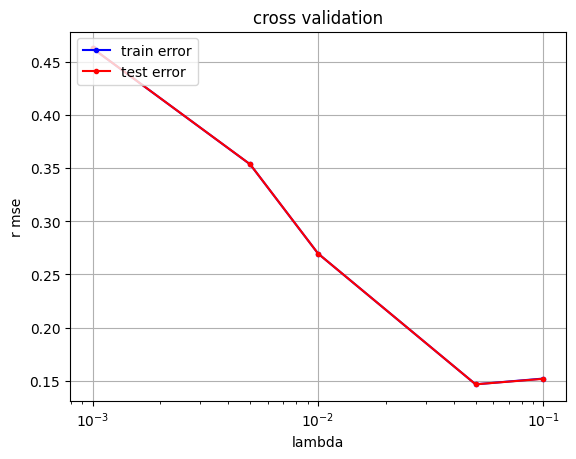

In [83]:
k_fold = 10
gammas = [0.001, 0.005 ,0.01, 0.05,0.1] #np.logspace(-4, 0, 30)
max_iters = 50
batch_size = 250

best_gamma, best_mse = cross_validation_demo(y_train_clean, x_train_clean, k_fold, gammas, max_iters, batch_size)

### SGD with **L2 regularization** & Cross Validation on gammas

In [86]:
def compute_gradient_reg(y, tx, w, lambda_):
    """Computes the gradient at w.

    Args:
        y: shape=(N, )
        tx: shape=(N,2)
        w: shape=(2, ). The vector of model parameters.

    Returns:
        An array of shape (2, ) (same shape as w), containing the gradient of the loss at w.
    """
    e = y - tx @ w

    reg = lambda_ * w.copy()
    reg[0] = 0  # excluding intercept

    grad = -(tx.T @ e) / len(e) + reg
    return grad

In [87]:
def stochastic_gradient_descent_with_reg(y, tx, initial_w, batch_size, max_iters, gamma, lambda_):
    """The Stochastic Gradient Descent algorithm (SGD).

    Args:
        y: shape=(N, )
        tx: shape=(N,2)
        initial_w: shape=(2, ). The initial guess (or the initialization) for the model parameters
        batch_size: a scalar denoting the number of data points in a mini-batch used for computing the stochastic gradient
        max_iters: a scalar denoting the total number of iterations of SGD
        gamma: a scalar denoting the stepsize

    Returns:
        losses: a list of length max_iters containing the loss value (scalar) for each iteration of SGD
        ws: a list of length max_iters containing the model parameters as numpy arrays of shape (2, ), for each iteration of SGD
    """

    # Define parameters to store w and loss
    ws = [initial_w]
    losses = []
    w = initial_w

    for n_iter in range(max_iters):
        for y_batch, tx_batch in batch_iter(
            y, tx, batch_size=batch_size, num_batches=1
        ):
            # compute a stochastic gradient and loss
            grad = compute_gradient_reg(y_batch, tx_batch, w, lambda_)
            w = w - gamma * grad

            loss = compute_loss(y, tx, w, "mse")
            # store w and loss
            ws.append(w)
            losses.append(loss)

        print(
            "SGD iter. {bi}/{ti}: loss={l}, norm_w ={norm_w}".format(
                bi=n_iter, ti=max_iters - 1, l=loss, norm_w = np.linalg.norm(w)
            )
        )
    return w, loss

In [88]:
def cross_validation_with_reg(y, x, k_indices, k, gamma, max_iters, batch_size, lambda_):
    """return the loss of ridge regression for a fold corresponding to k_indices

    Args:
        y:          shape=(N,)
        x:          shape=(N,)
        k_indices:  2D array returned by build_k_indices()
        k:          scalar, the k-th fold (N.B.: not to confused with k_fold which is the fold nums)
        lambda_:    scalar, cf. ridge_regression()
        degree:     scalar, cf. build_poly()

    Returns:
        train and test root mean square errors rmse = sqrt(2 mse)

    >>> cross_validation(np.array([1.,2.,3.,4.]), np.array([6.,7.,8.,9.]), np.array([[3,2], [0,1]]), 1, 2, 3)
    (0.019866645527596753, 0.33555914361295197)
    """

    ### SOLUTION
    # get k'th subgroup in test, others in train
    te_indice = k_indices[k]
    tr_indice = k_indices[~(np.arange(k_indices.shape[0]) == k)]
    tr_indice = tr_indice.reshape(-1)
    y_te = y[te_indice]
    y_tr = y[tr_indice]
    x_te = x[te_indice]
    x_tr = x[tr_indice]
    # form data with constant
    tx_tr = np.c_[np.ones(x_tr.shape[0]), x_tr]
    tx_te = np.c_[np.ones(x_te.shape[0]), x_te]
    # SGD
    w_initial = np.zeros(tx_tr.shape[1])

    w, loss_tr = stochastic_gradient_descent_with_reg(y_tr, tx_tr, w_initial, batch_size, max_iters, gamma ,lambda_)
    # calculate the loss for train and test data
    loss_te = compute_loss(y_te, tx_te, w)
    return float(loss_tr), float(loss_te)

In [94]:
from plots import cross_validation_visualization


def cross_validation_demo_with_reg(y, x, k_fold, gammas, max_iters, batch_size, lambda_):
    """cross validation over regularisation parameter lambda.

    Args:
        degree: integer, degree of the polynomial expansion
        k_fold: integer, the number of folds
        lambdas: shape = (p, ) where p is the number of values of lambda to test
    Returns:
        best_lambda : scalar, value of the best lambda
        best_rmse : scalar, the associated root mean squared error for the best lambda
    """

    seed = 12
    k_fold = k_fold
    # split data in k fold
    k_indices = build_k_indices(y, k_fold, seed)
    # define lists to store the loss of training data and test data
    rmse_tr = []
    rmse_te = []
    ### SOLUTION
    # cross validation
    for gamma in gammas:
        print("Computing gamma=", gamma, "----------------------------")
        rmse_tr_tmp = []
        rmse_te_tmp = []
        for k in range(k_fold):
            loss_tr, loss_te = cross_validation_with_reg(y, x, k_indices, k, gamma, max_iters, batch_size, lambda_)
            rmse_tr_tmp.append(loss_tr)
            rmse_te_tmp.append(loss_te)
        rmse_tr.append(np.mean(rmse_tr_tmp))
        rmse_te.append(np.mean(rmse_te_tmp))
    best_gamma, best_rmse = gammas[np.argmin(rmse_te)], np.min(rmse_te)
 

    cross_validation_visualization(gammas, rmse_tr, rmse_te)
    print(
        "For SGD, the choice of gamma which leads to the best test mse is %.5f with a test mse of %.3f"
        % (best_gamma, best_rmse)
    )
    return best_gamma, best_rmse

Computing gamma= 0.001 ----------------------------
SGD iter. 0/49: loss=0.4992214182081199, norm_w =0.0010553771111940294
SGD iter. 1/49: loss=0.4984378328284988, norm_w =0.0018880727139907758
SGD iter. 2/49: loss=0.497638813516475, norm_w =0.0027422261043086225
SGD iter. 3/49: loss=0.4967616933715328, norm_w =0.003723591795420465
SGD iter. 4/49: loss=0.4959426409793371, norm_w =0.004732579554955893
SGD iter. 5/49: loss=0.4951363429303268, norm_w =0.005599243220435661
SGD iter. 6/49: loss=0.49428681526492735, norm_w =0.006556690417866018
SGD iter. 7/49: loss=0.4935814840765189, norm_w =0.007321949051222728
SGD iter. 8/49: loss=0.4927612699324192, norm_w =0.008287804717406746
SGD iter. 9/49: loss=0.4919929836087223, norm_w =0.009133578325214324
SGD iter. 10/49: loss=0.4912025560460918, norm_w =0.010022698960608189
SGD iter. 11/49: loss=0.49037793203804214, norm_w =0.010918001189369796
SGD iter. 12/49: loss=0.48960685675074184, norm_w =0.0118204914361095
SGD iter. 13/49: loss=0.48880022

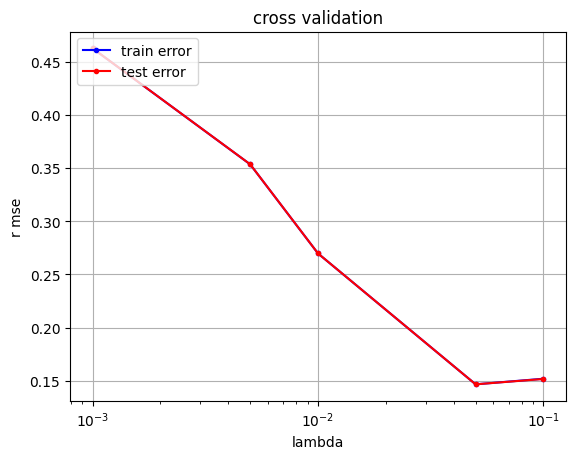

In [96]:
k_fold = 10
gammas = [0.001, 0.005 ,0.01, 0.05,0.1] #np.logspace(-4, 0, 30)
max_iters = 50
batch_size = 250
lambda_ = 0.05

best_gamma, best_mse = cross_validation_demo_with_reg(y_train_clean, x_train_clean, k_fold, gammas, max_iters, batch_size,lambda_)

### L2 Reg-SGD with Cross Validation over **gamma** & **lambda_**

In [ ]:
def best_gamma_lambda_selection(y,x, k_fold, gammas, max_iters, batch_size, lambdas, seed=1):
    """cross validation over regularisation parameter lambda and degree.

    Args:
        degrees: shape = (d,), where d is the number of degrees to test
        k_fold: integer, the number of folds
        lambdas: shape = (p, ) where p is the number of values of lambda to test
    Returns:
        best_degree : integer, value of the best degree
        best_lambda : scalar, value of the best lambda
        best_rmse : value of the rmse for the couple (best_degree, best_lambda)

    >>> best_degree_selection(np.arange(2,11), 4, np.logspace(-4, 0, 30))
    (7, 0.004520353656360241, 0.2895728056656946)
    """

    # split data in k fold
    k_indices = build_k_indices(y, k_fold, seed)

    # for each degree, we compute the best lambdas and the associated rmse
    best_lambdas = []
    best_rmses = []

    # vary degree
    for gamma in gammas:
        print('Computing gamma: ', gamma, '###################')
        # cross validation
        rmse_te = []
        for lambda_ in lambdas:
            print(f'Computing gamma: {gamma} & lambda: {lambda_}-------------')
            rmse_te_tmp = []
            for k in range(k_fold):
                _, loss_te = cross_validation_with_reg(y, x, k_indices, k, gamma, max_iters, batch_size, lambda_)
                rmse_te_tmp.append(loss_te)
            rmse_te.append(np.mean(rmse_te_tmp))

        ind_lambda_opt = np.argmin(rmse_te)
        best_lambdas.append(lambdas[ind_lambda_opt])
        best_rmses.append(rmse_te[ind_lambda_opt])

    ind_best_gamma = np.argmin(best_rmses)
    best_gamma = gammas[ind_best_gamma]
    best_lambda = best_lambdas[ind_best_gamma]
    best_rmse = best_rmses[ind_best_gamma]

    return int(best_gamma), float(best_lambda), float(best_rmse)

In [ ]:
k_fold = 10
gammas = [0.001, 0.005 ,0.01, 0.05,0.1] #np.logspace(-4, 0, 30)
max_iters = 50
batch_size = 250
lambdas = [0.001, 0.01, 0.1,1]

best_gamma, best_lambda, best_mse = best_gamma_lambda_selection(y_train_clean, x_train_clean, k_fold, gammas, max_iters, batch_size, lambdas)

Computing gamma:  0.001 ###################
Computing gamma: 0.001 & lambda: 0.001-------------
SGD iter. 0/49: loss=0.49926007549185625, norm_w =0.0010606900075002521
SGD iter. 1/49: loss=0.49849429399725737, norm_w =0.002002026452616374
SGD iter. 2/49: loss=0.49767284528142114, norm_w =0.0028980752887904637
SGD iter. 3/49: loss=0.4969632884835326, norm_w =0.00363765805845729
SGD iter. 4/49: loss=0.496074186160925, norm_w =0.004571503436357021
SGD iter. 5/49: loss=0.4952248129063369, norm_w =0.005598345806690887
SGD iter. 6/49: loss=0.49440072297441023, norm_w =0.006590639794318482
SGD iter. 7/49: loss=0.49365336538777754, norm_w =0.00742868167327697
SGD iter. 8/49: loss=0.4928455713180127, norm_w =0.008354262760865606
SGD iter. 9/49: loss=0.49211677952648003, norm_w =0.009111982494421062
SGD iter. 10/49: loss=0.49136643775162203, norm_w =0.009907696920313737
SGD iter. 11/49: loss=0.4905689385300913, norm_w =0.010775909841607104
SGD iter. 12/49: loss=0.4897811468383965, norm_w =0.0116

In [100]:
print(best_gamma, best_lambda, best_mse)

0 0.001 0.14655232071525978
